# Final review — code demonstration
**Generative floorplan synthesis on CubiCasa5K: DAE vs VAE vs GNN**

This notebook is the demo the rubric asks for:

1. load the cached data and verify every hand-written backward pass,
2. **live-train** each model for a few epochs (written to `models/demo/`, so the submitted checkpoints are never overwritten),
3. load the **best checkpoints** (lowest validation loss) and **benchmark them on the unseen test set**,
4. show the loss curves, ROC curves, confusion matrices and failure analysis.

All models are NumPy code written from scratch, in the `floorplan/` package (see `README.md`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from floorplan import config as C
from floorplan.data import load_splits, fixed_noisy_sets
from floorplan.models import build_model
from floorplan.trainer import fit
from floorplan.checkpoint import load_checkpoint
from floorplan.analysis import evaluate_model, baseline_rows
from floorplan.gradcheck import gradient_check

X_train, X_val, X_test = load_splits()
val_noisy, test_noisy = fixed_noisy_sets(X_val, X_test)

Loaded splits  train (4200, 1024)  val (400, 1024)  test (400, 1024)  | wall pixels 12.64%


## 1. Are the hand-written gradients correct?

In [2]:
for name in ("DAE", "VAE", "GNN"):
    gradient_check(name, seed=0)

  DAE: 14 tensors, 157 smooth probes (0 on ReLU kinks discarded), worst tolerance ratio 0.000 -> CORRECT


  VAE: 16 tensors, 181 smooth probes (0 on ReLU kinks discarded), worst tolerance ratio 0.000 -> CORRECT


  GNN: 12 tensors, 144 smooth probes (0 on ReLU kinks discarded), worst tolerance ratio 0.000 -> CORRECT


## 2. Live training (a few epochs per model)
Change any argument here during the demo, e.g. `n_layers=2` for the GNN, `beta=4.0` for the VAE or `width=8` for the DAE.

In [3]:
LIVE = {"DAE": dict(width=16), "VAE": dict(width=16, beta=1.0), "GNN": dict(hidden=64, n_layers=6)}
EPOCHS = {"DAE": 2, "VAE": 2, "GNN": 3}
live_hist = {}
for name, kw in LIVE.items():
    model = build_model(name, **kw)
    print(f"{name}: {model.n_params():,} parameters")
    live_hist[name] = fit(model, X_train, X_val, val_noisy, epochs=EPOCHS[name], print_every=1,
                          ckpt_path=C.MODELS_DIR / "demo" / f"best_{name.lower()}.npz",
                          kl_warmup=C.VAE_KL_WARMUP if name == "VAE" else 0)

DAE: 21,025 parameters


  [DAE] epoch   1/2  train=0.6034  val_loss=0.5801  val_F1@0.5=0.4081  *best  [3s]


  [DAE] epoch   2/2  train=0.5603  val_loss=0.5500  val_F1@0.5=0.4168  *best  [6s]
  [DAE] best epoch 2 (val_loss 0.5500) -> saved best_dae.npz
VAE: 25,649 parameters


  [VAE] epoch   1/2  train=0.6372  kl=75.83  val_loss=0.5813  val_F1@0.5=0.3821  [3s]


  [VAE] epoch   2/2  train=0.5958  kl=79.69  val_loss=0.5628  val_F1@0.5=0.3978  *best  [6s]
  [VAE] best epoch 2 (val_loss 0.5628) -> saved best_vae.npz
GNN: 51,792 parameters


  [GNN] epoch   1/3  train=0.5622  val_loss=0.5225  val_F1@0.5=0.4892  *best  [2s]


  [GNN] epoch   2/3  train=0.5133  val_loss=0.5069  val_F1@0.5=0.4674  *best  [4s]


  [GNN] epoch   3/3  train=0.5047  val_loss=0.5026  val_F1@0.5=0.4839  *best  [6s]
  [GNN] best epoch 3 (val_loss 0.5026) -> saved best_gnn.npz


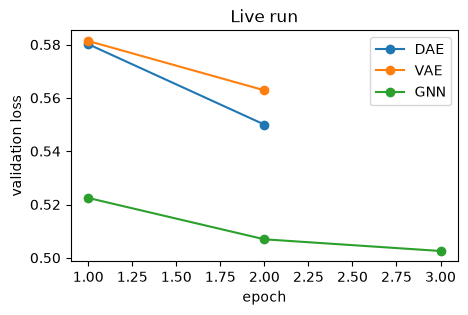

In [4]:
fig, ax = plt.subplots(figsize=(5, 3))
for name, h in live_hist.items():
    ax.plot(h["epoch"], h["val_loss"], "o-", label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("validation loss"); ax.set_title("Live run"); ax.legend(); plt.show()

## 3. Benchmark the BEST checkpoints on the unseen test set
The threshold for every model is tuned on validation and then frozen.

In [5]:
rows = []
for name, res in baseline_rows(X_val, val_noisy, X_test, test_noisy, X_train.mean()).items():
    rows.append(dict(model=name, **res["test"]))
for name in ("DAE", "VAE", "GNN"):
    model, meta = load_checkpoint(C.MODELS_DIR / f"best_{name.lower()}.npz")
    res, _, _, thr = evaluate_model(model, X_val, val_noisy, X_test, test_noisy)
    rows.append(dict(model=name, best_epoch=meta["epoch"], params=model.n_params(), **res["test"]))
cols = ["model", "best_epoch", "params", "threshold", "wall_precision", "wall_recall", "wall_f1", "wall_iou", "roc_auc", "accuracy"]
pd.DataFrame(rows)[cols].round(4)

,model,best_epoch,params,threshold,wall_precision,wall_recall,wall_f1,wall_iou,roc_auc,accuracy
0,copy_input,NaN,NaN,0.50,1.0000,0.1998,0.3330,0.1998,0.5999,0.8925
1,blank,NaN,NaN,0.50,0.0000,0.0000,0.0000,0.0000,0.5000,0.8657
2,DAE,90.0,21025.0,0.65,0.4302,0.6003,0.5012,0.3344,0.8305,0.8396
3,VAE,81.0,25649.0,0.65,0.4217,0.6076,0.4978,0.3314,0.8284,0.8354
4,GNN,84.0,51792.0,0.70,0.6308,0.5339,0.5783,0.4068,0.8554,0.8954


## 4. Training curves of the submitted runs, ROC and confusion matrices

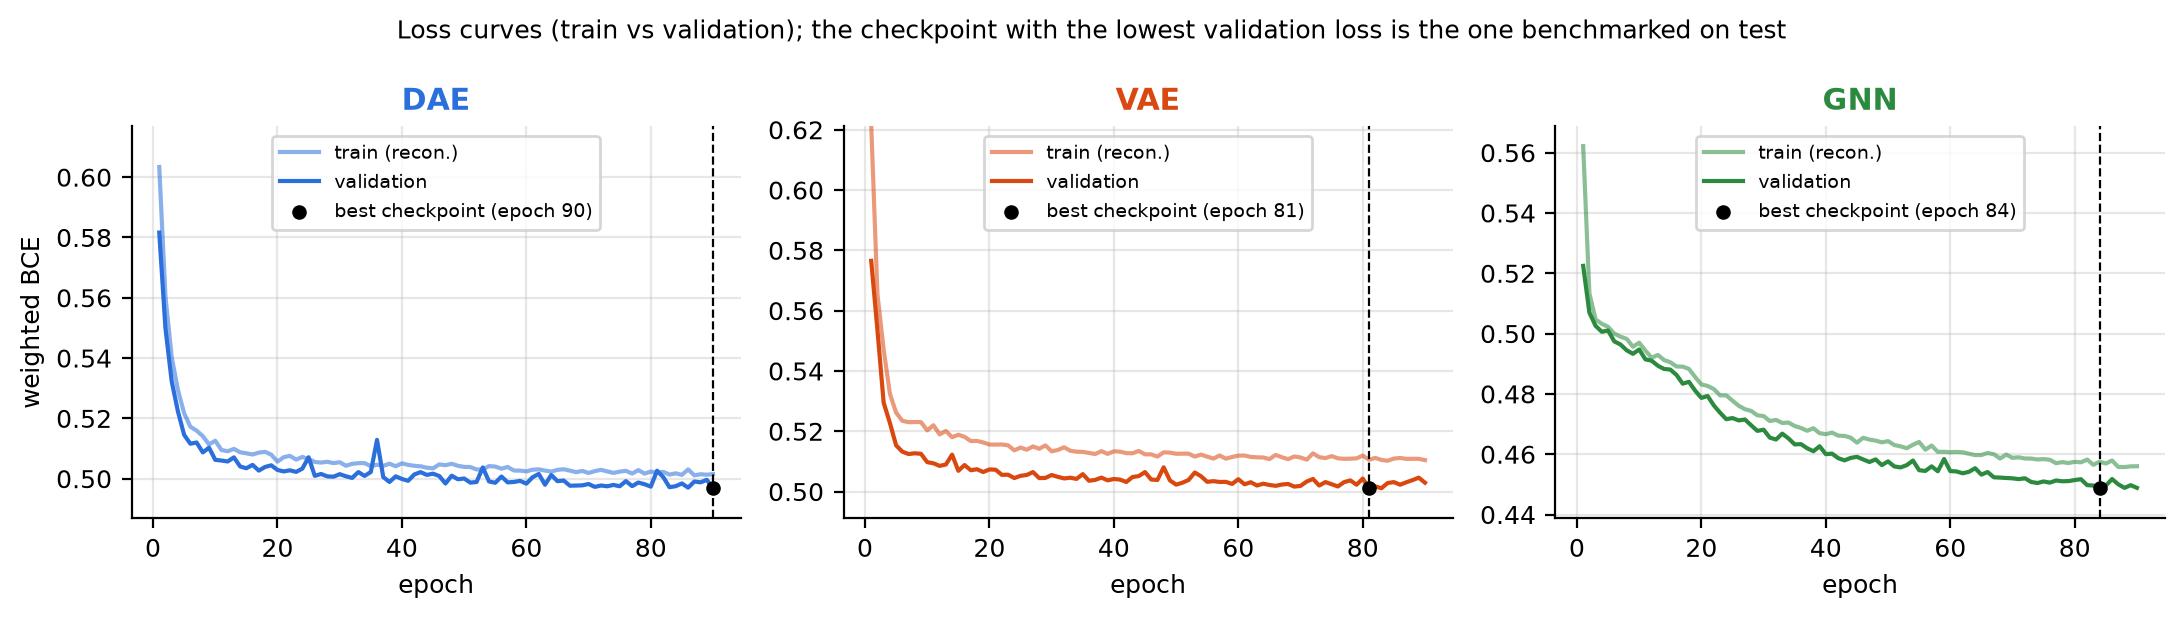

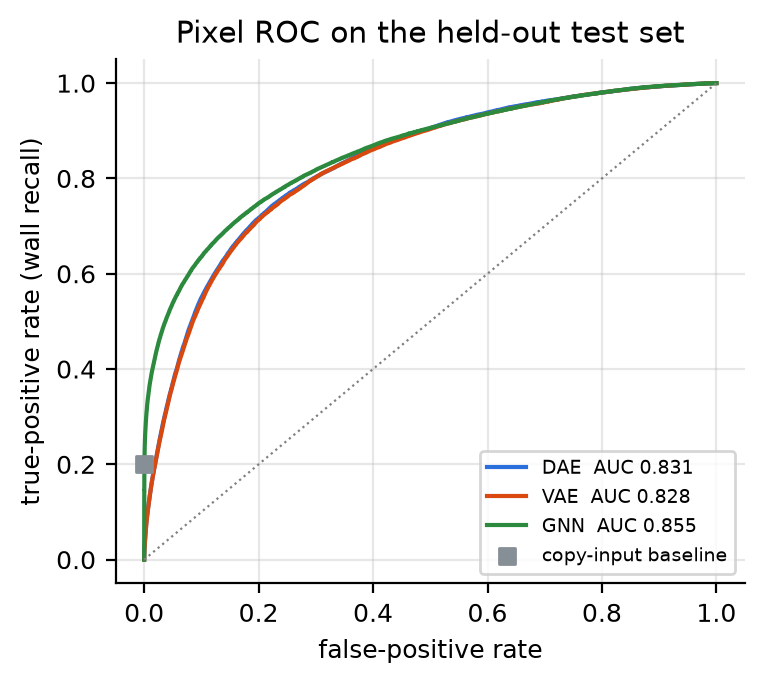

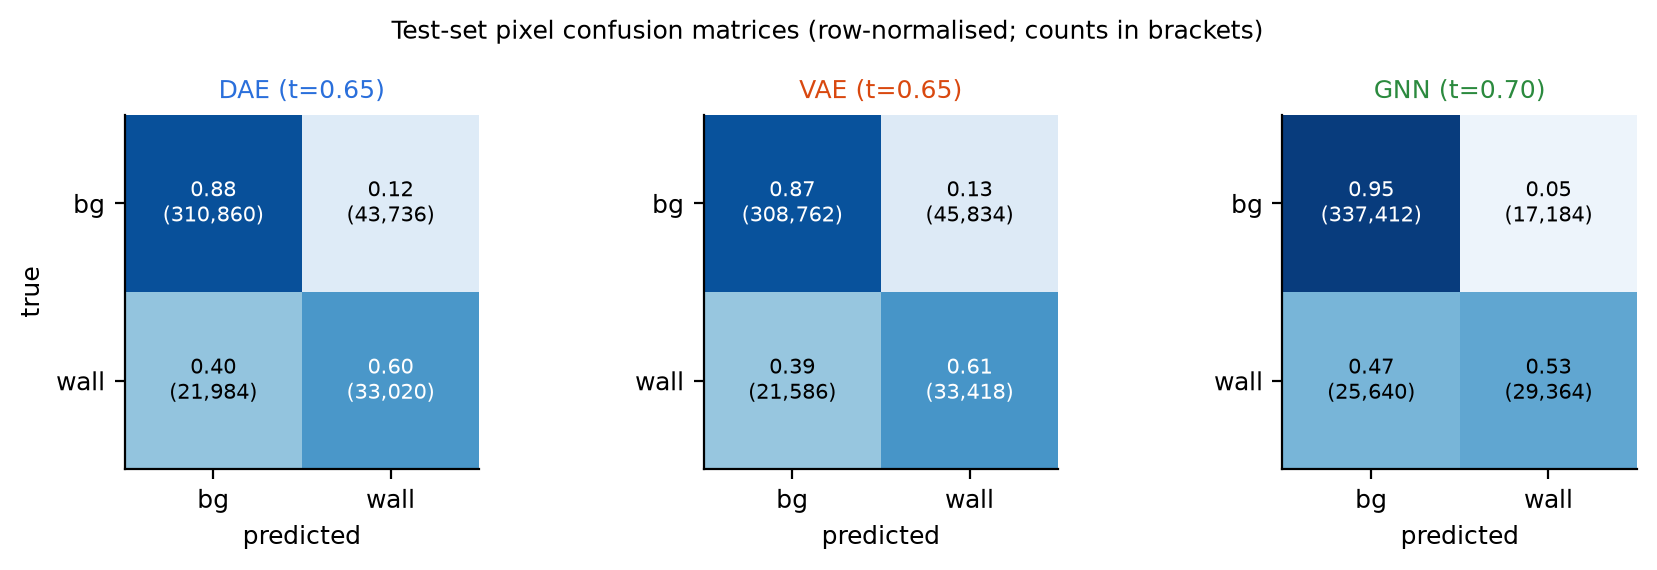

In [6]:
for f in ["fig_training_curves.png", "fig_roc.png", "fig_confusion.png"]:
    display(Image(filename=str(C.FIGURES_DIR / f), width=820))

## 5. Failure analysis and generation

,model,fp_thickening,fp_hallucination,fn_erased,fn_ignored,observed_walls_kept,pred_wall_fraction,true_wall_fraction,f1_patch_border,f1_patch_interior,plan_f1_mean,plan_f1_p10,plan_f1_p90,plan_f1_vs_density_corr
0,DAE,0.688,0.107,0.391,0.009,0.954,0.187,0.134,0.499,0.508,0.458,0.314,0.583,0.710
1,VAE,0.710,0.123,0.380,0.012,0.938,0.193,0.134,0.495,0.506,0.454,0.318,0.579,0.716
2,GNN,0.250,0.063,0.466,0.000,1.000,0.114,0.134,0.577,0.582,0.535,0.377,0.694,0.545
3,copy_input,0.000,0.000,0.800,0.000,1.000,0.027,0.134,0.333,0.333,0.330,0.261,0.403,0.044


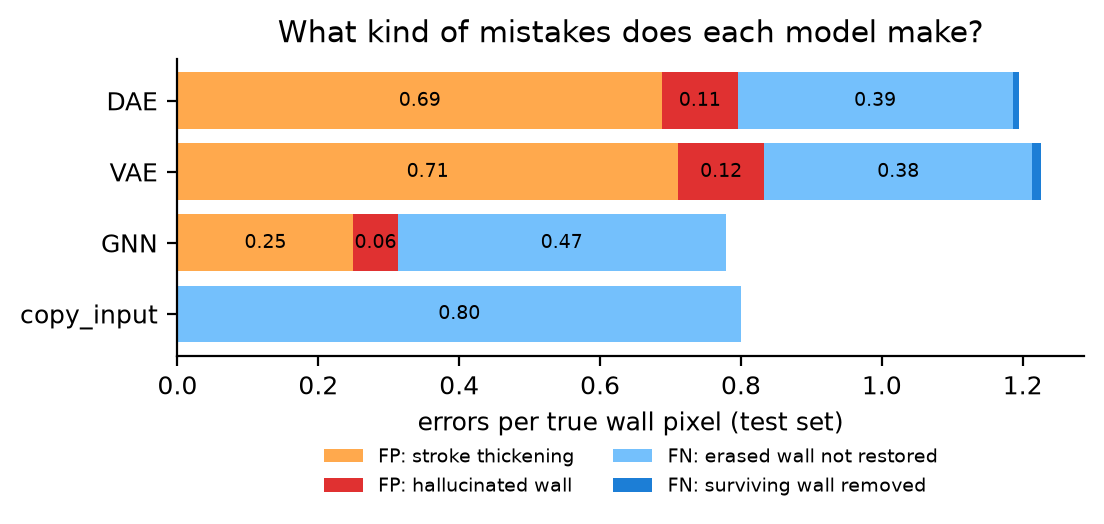

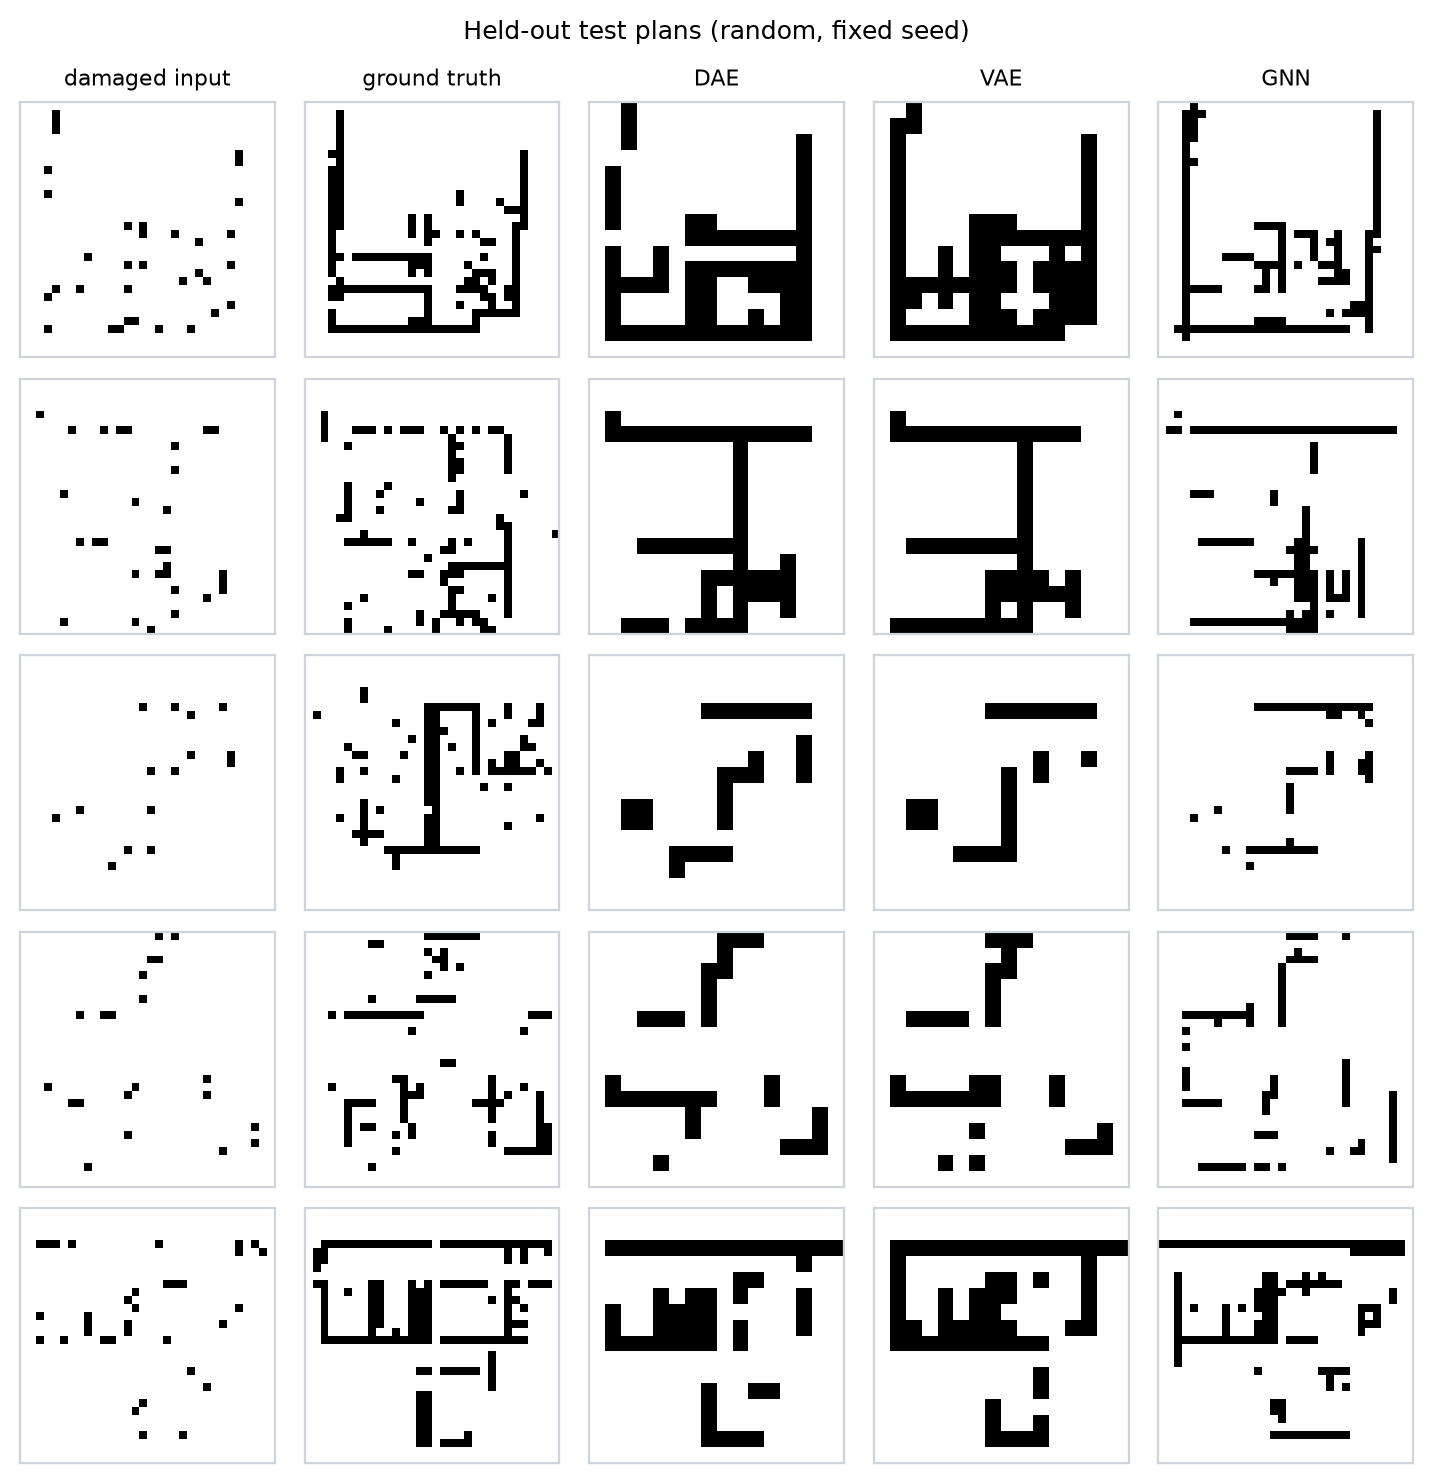

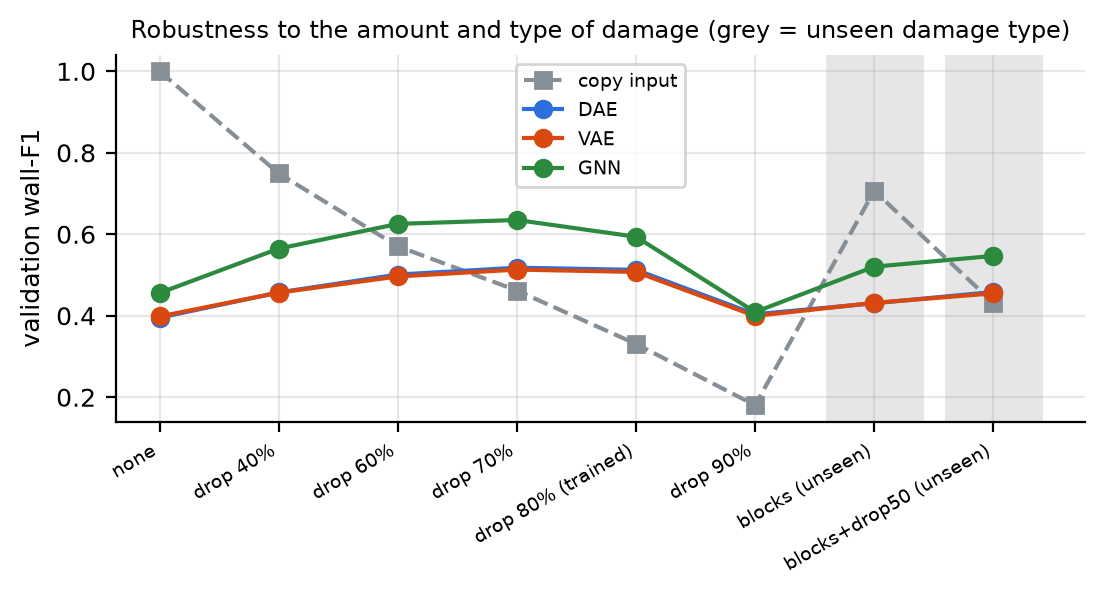

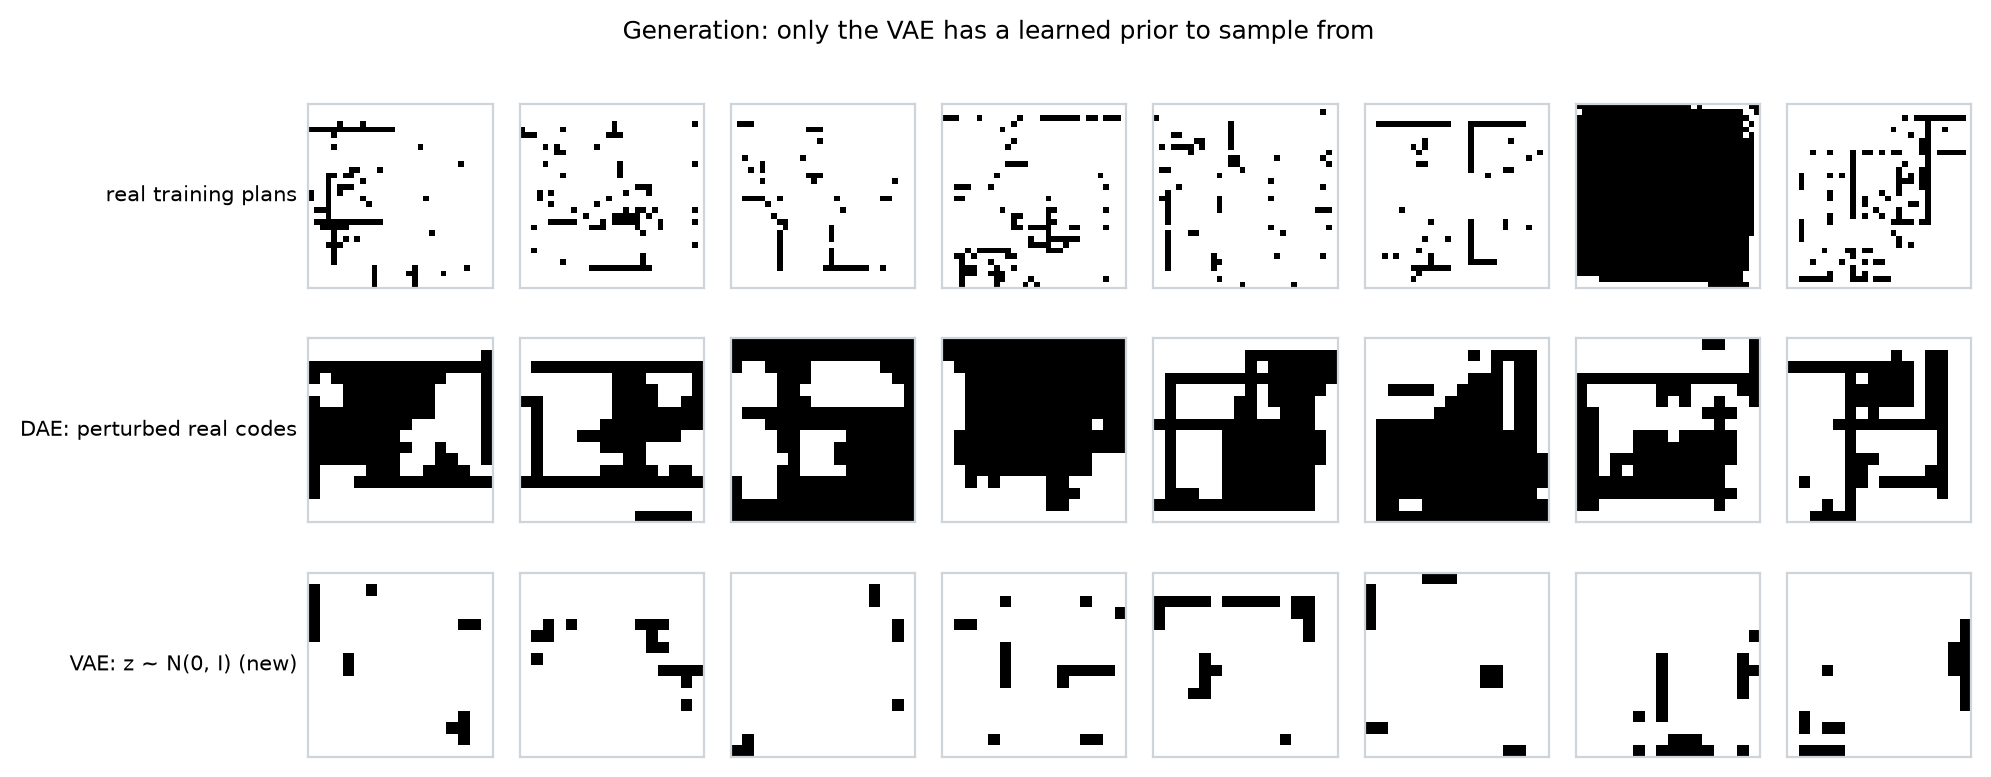

In [7]:
display(pd.read_csv(C.RESULTS_DIR / "error_analysis.csv").round(3))
for f in ["fig_error_breakdown.png", "fig_qualitative.png", "fig_damage_sweep.png", "fig_generation.png"]:
    display(Image(filename=str(C.FIGURES_DIR / f), width=760))

In [8]:
display(pd.read_csv(C.RESULTS_DIR / "generation.csv").round(4))
display(pd.read_csv(C.RESULTS_DIR / "selection_vae_beta.csv").drop(columns=["path"]).round(4))
display(pd.read_csv(C.RESULTS_DIR / "selection_gnn_layers.csv").drop(columns=["path"]).round(4))

,source,wall_fraction,line_continuity,diversity,nn_train_distance
0,real training plans,0.1281,61.2088,0.2290,0.0000
1,real test plans (reference),0.1343,63.8250,0.2377,0.1247
2,DAE test reconstructions,0.1874,147.8850,0.3101,0.1591
3,VAE test reconstructions,0.1935,154.3025,0.3238,0.1635
4,GNN test reconstructions,0.1136,64.2487,0.2029,0.1024
5,DAE perturbed-code samples,0.5167,472.8725,0.4812,0.2670
6,"VAE prior samples z~N(0,I)",0.0941,68.0625,0.1744,0.0941


,beta,best_epoch,val_loss,threshold,val_wall_f1,val_auc,active_units,latent_units,prior_wall_fraction,real_wall_fraction,qualifies,selected
0,0.1,81,0.5011,0.65,0.5075,0.8340,238,256,0.0977,0.1264,True,True
1,0.5,63,0.5065,0.65,0.4981,0.8307,159,256,0.1300,0.1264,True,False
2,1.0,63,0.5124,0.65,0.4902,0.8268,154,256,0.1305,0.1264,True,False
3,4.0,66,0.5755,0.55,0.4013,0.7715,78,256,0.2344,0.1264,False,False


,n_layers,best_epoch,val_loss,threshold,val_wall_f1,val_auc,receptive_px,params,selected
0,2,86,0.4632,0.7,0.5764,0.8503,20,18768,False
1,4,89,0.4515,0.7,0.5879,0.8589,36,35280,False
2,6,84,0.4487,0.7,0.5938,0.8614,52,51792,True


## 6. Second experiment: official wall labels
Same models and protocol, but the target is now only the annotated **wall polygons** of `model.svg`
(no text, furniture or dimension lines). Everything for this experiment lives in `models/walls/`,
`results/walls/` and `figures/walls/`.

In [9]:
C.set_labels("walls")
Xw_train, Xw_val, Xw_test = load_splits()
wv_noisy, wt_noisy = fixed_noisy_sets(Xw_val, Xw_test)
rows = []
for name, res in baseline_rows(Xw_val, wv_noisy, Xw_test, wt_noisy, Xw_train.mean()).items():
    rows.append(dict(model=name, **res["test"]))
for name in ("DAE", "VAE", "GNN"):
    model, meta = load_checkpoint(C.MODELS_DIR / f"best_{name.lower()}.npz")
    res, _, _, thr = evaluate_model(model, Xw_val, wv_noisy, Xw_test, wt_noisy)
    rows.append(dict(model=name, best_epoch=meta["epoch"], params=model.n_params(), **res["test"]))
pd.DataFrame(rows)[cols].round(4)

Loaded splits  train (4200, 1024)  val (400, 1024)  test (400, 1024)  | wall pixels 18.67%


,model,best_epoch,params,threshold,wall_precision,wall_recall,wall_f1,wall_iou,roc_auc,accuracy
0,copy_input,NaN,NaN,0.50,1.0000,0.1983,0.3310,0.1983,0.5992,0.8474
1,blank,NaN,NaN,0.50,0.0000,0.0000,0.0000,0.0000,0.5000,0.8096
2,DAE,84.0,21025.0,0.75,0.5631,0.7860,0.6561,0.4882,0.9024,0.8431
3,VAE,82.0,25649.0,0.70,0.5481,0.8103,0.6539,0.4858,0.9002,0.8367
4,GNN,89.0,51792.0,0.80,0.8397,0.7397,0.7865,0.6481,0.9450,0.9235


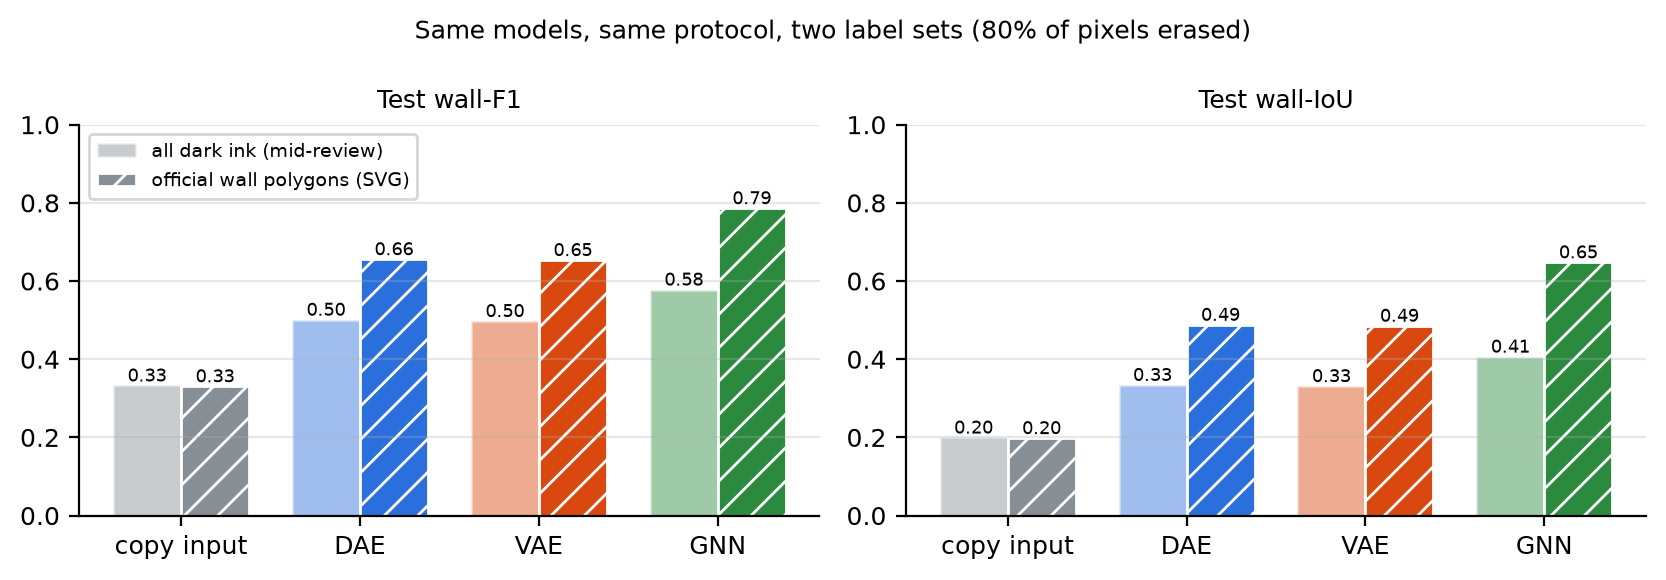

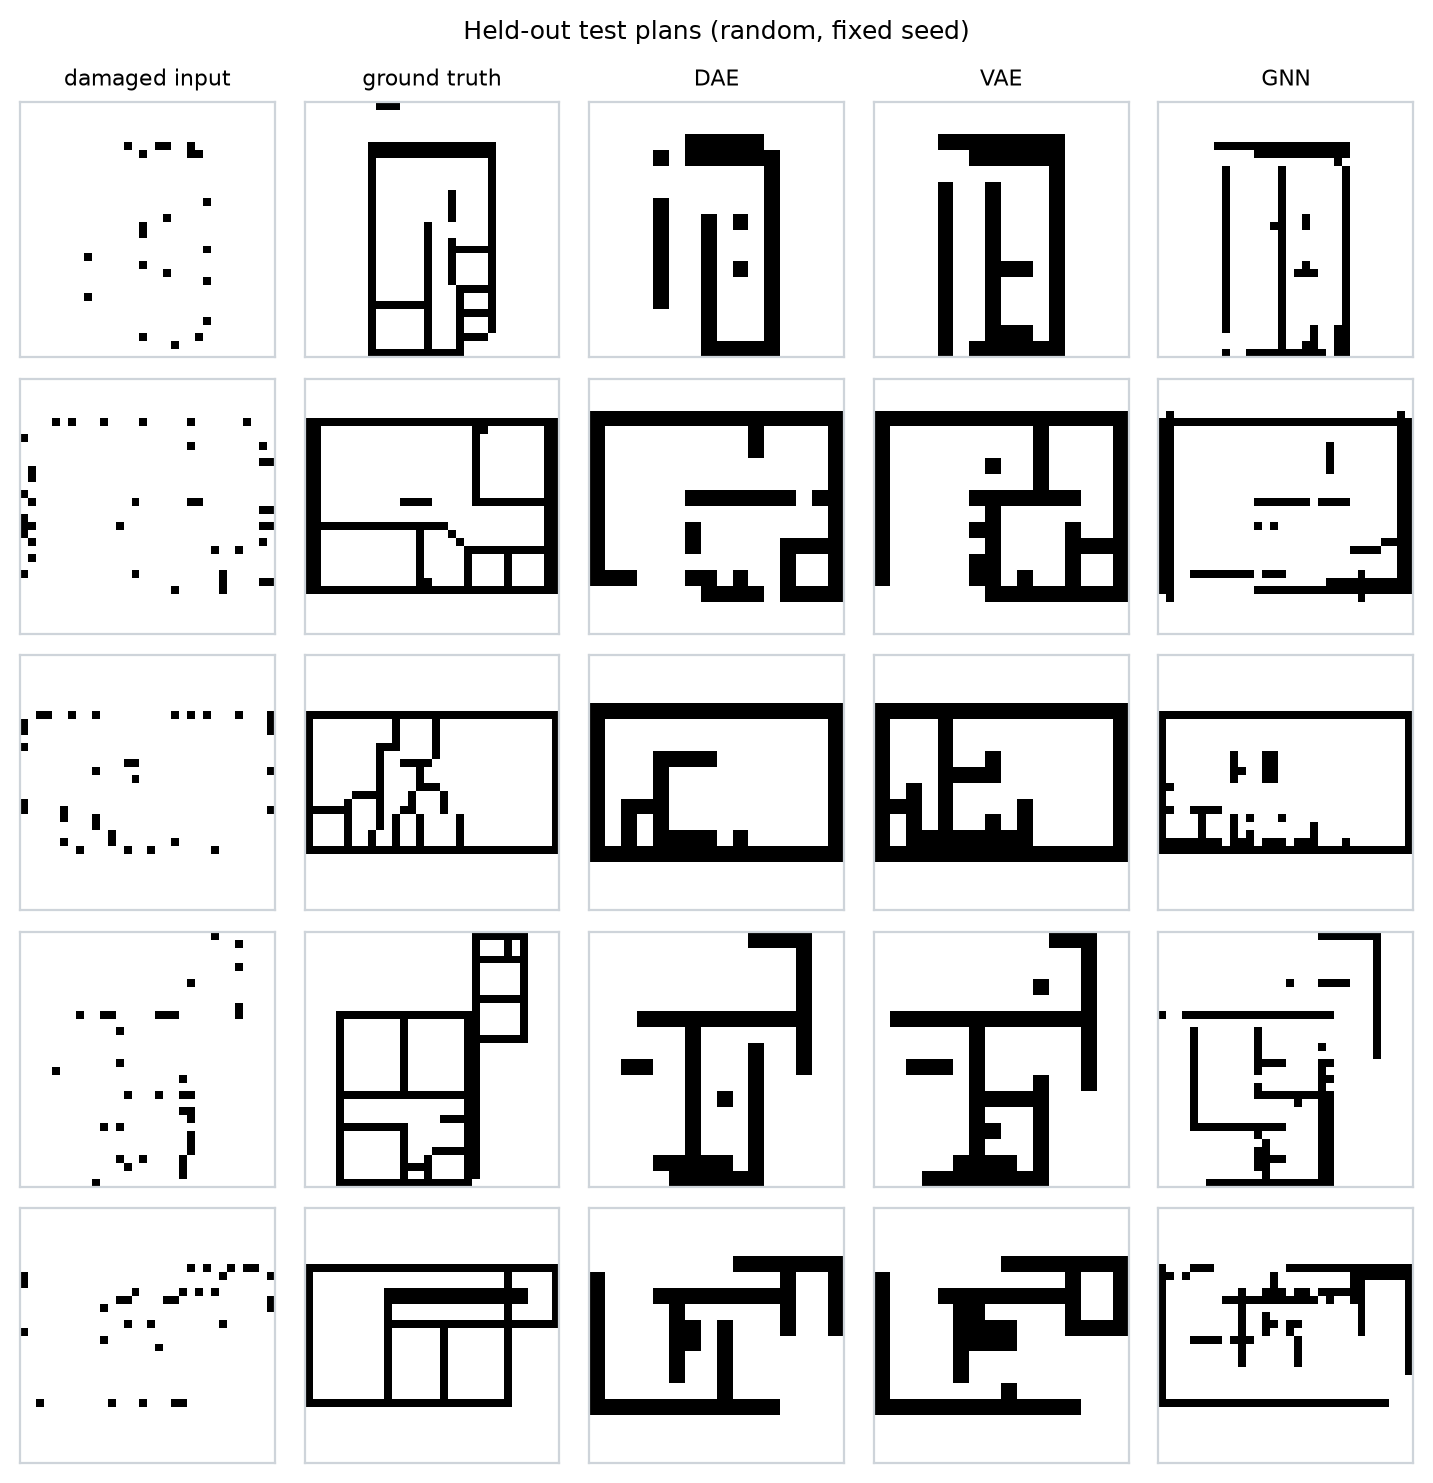

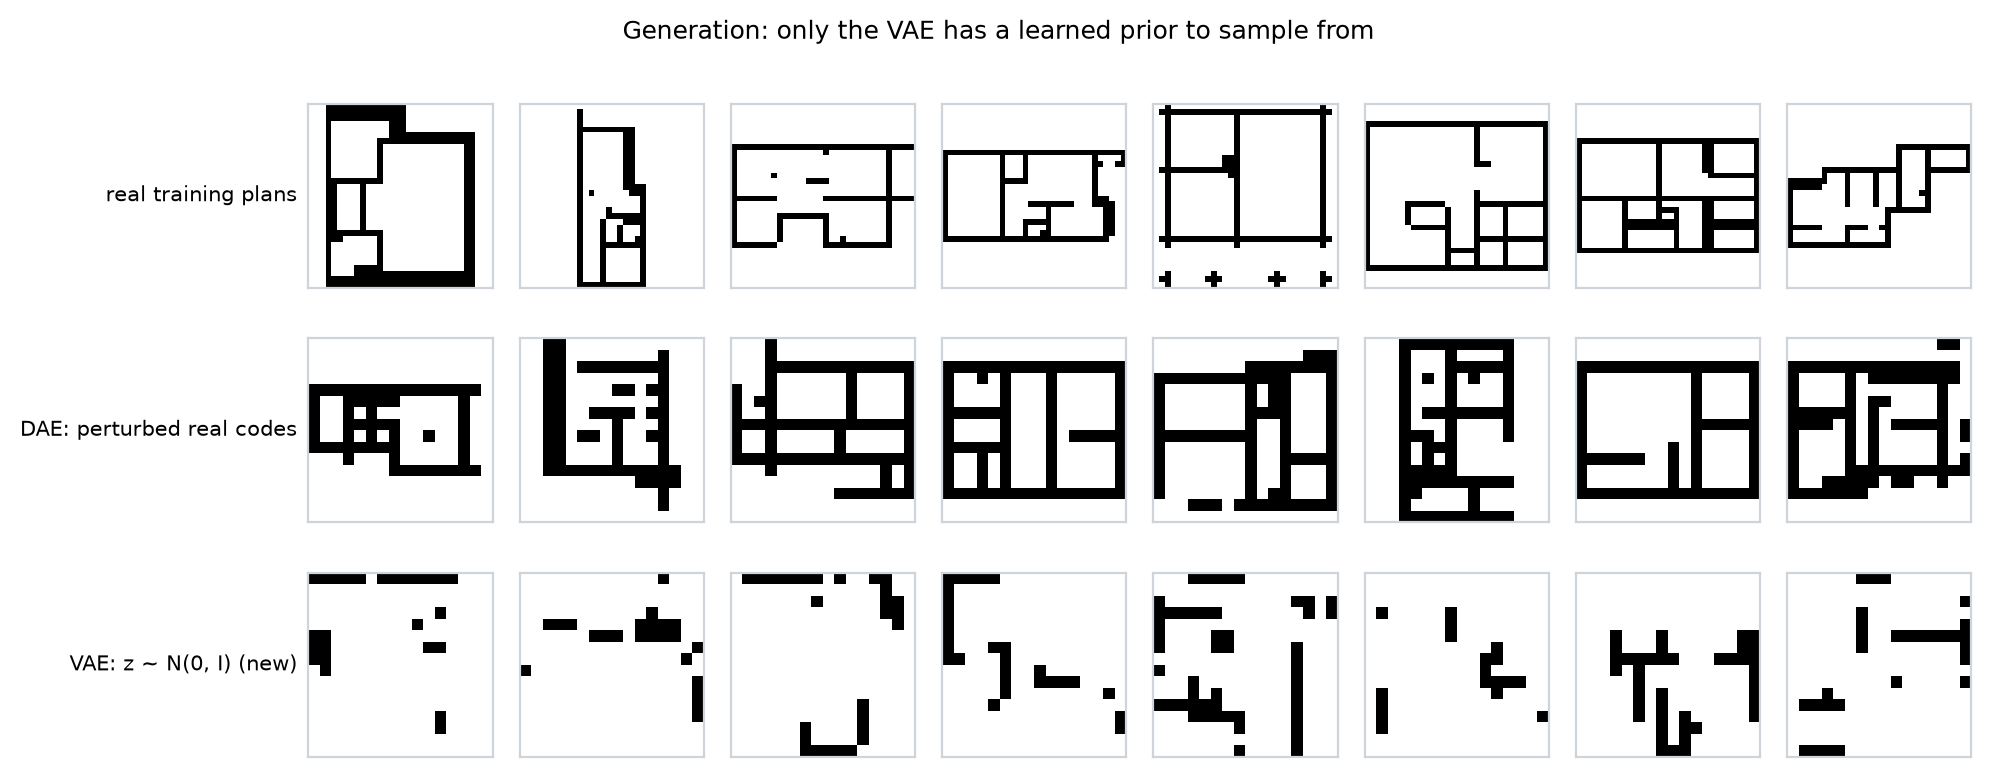

In [10]:
for f in [C.PROJECT_DIR / "figures" / "fig_labels_comparison.png",
          C.FIGURES_DIR / "fig_qualitative.png", C.FIGURES_DIR / "fig_generation.png"]:
    display(Image(filename=str(f), width=760))